In [31]:
import pandas as pd
import yfinance as yf
import numpy as np



# 1. Download dati giornalieri, 8 anni
ticker = "DOGE-USD"
df = yf.download(ticker, period="8y", interval="1d")

# Pulizia del MultiIndex
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

[*********************100%***********************]  1 of 1 completed


In [32]:
# 2. Calcolo degli indicatori di base
window = 30  # Finestra di 30 giorni per la media mobile dei volumi
df["Volume_MA"] = df["Volume"].rolling(window=window).mean()
df["Volume_STD"] = df["Volume"].rolling(window=window).std()

# Variazione percentuale giornaliera del prezzo
df["Price_Change_Pct"] = df["Close"].pct_change() * 100

# MEDIA MOBILE A 7 GIORNI FINO AL GIORNO -1 (Spostata di 1 giorno nel passato per non essere influenzato dal Pump)
# Usiamo il valore assoluto per misurare l'ampiezza media dell'oscillazione giornaliera recente
df["Price_Change_Abs_MA7_Lag1"] = (
    df["Price_Change_Pct"].abs().shift(1).rolling(window=7).mean()
)

# 3. Definizione delle condizioni di "Pump", per essere considerato pump deve avere:
# - Volume superiore alla media + 4 volte la deviazione standard
# - Rialzo del prezzo giornaliero superiore al 15%
df["Volume_Anomaly"] = df["Volume"] > (df["Volume_MA"] + (4 * df["Volume_STD"]))
df["Pump_Candidate"] = df["Volume_Anomaly"] & (df["Price_Change_Pct"] > 15)

pumps = df[df["Pump_Candidate"]]

print(
    f"Trovati {len(pumps)} giorni con caratteristiche sospette di pump su {ticker}:"
)
print(
    pumps[
        [
            "Close",
            "Price_Change_Pct",
            "Price_Change_Abs_MA7_Lag1",
            "Volume",
            "Volume_MA",
        ]
    ]
)

Trovati 19 giorni con caratteristiche sospette di pump su DOGE-USD:
Price          Close  Price_Change_Pct  Price_Change_Abs_MA7_Lag1  \
Date                                                                
2019-04-01  0.002461         18.317313                   0.581861   
2019-04-04  0.003697         16.845760                   6.654426   
2019-07-05  0.003867         19.758446                   2.741483   
2020-07-08  0.004750         53.721677                   5.055169   
2020-11-24  0.004204         15.241223                   5.344775   
2020-12-20  0.004625         17.774388                   3.634886   
2021-01-02  0.010615         86.719422                   4.593773   
2021-01-28  0.034084        355.546631                   4.493524   
2021-01-29  0.047162         38.369911                  53.876250   
2021-04-01  0.061986         15.522673                   1.255150   
2021-04-14  0.121517         30.041199                  10.082971   
2021-04-16  0.365870        100.799

Già dai grafici di volume e prezzo si può intuire una correlazione tra volume e prezzo

<Axes: xlabel='Date'>

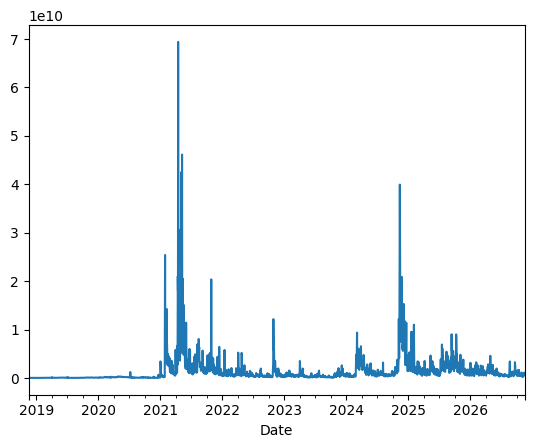

In [33]:
df['Volume'].plot()

<Axes: xlabel='Date'>

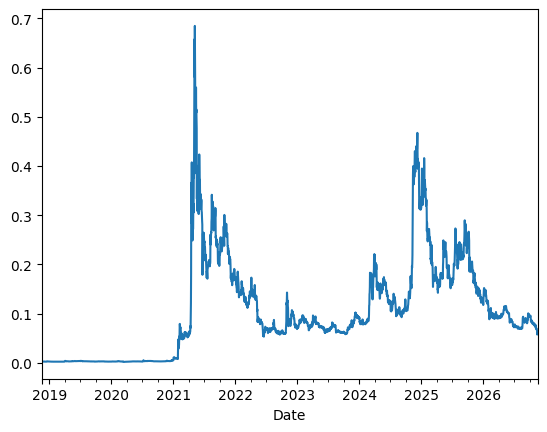

In [34]:
df['Close'].plot()

In [35]:
results = []
for date in pumps.index:
  idx = df.index.get_loc(date)

  # Prendiamo i prezzi dei 3 giorni successivi
  if idx + 3 < len(df):
    close_day_0 = df.loc[date, "Close"]
    close_day_1 = df.iloc[idx + 1]["Close"]
    close_day_3 = df.iloc[idx + 3]["Close"]

    return_1d = ((close_day_1 - close_day_0) / close_day_0) * 100
    return_3d = ((close_day_3 - close_day_0) / close_day_0) * 100
    pump_return = df.loc[date, "Price_Change_Pct"]

    # Estraiamo la media mobile a 7 giorni del giorno precedente (t-1)
    normal_volatility_ma7 = df.loc[date, "Price_Change_Abs_MA7_Lag1"]

    gain_retained_ratio = return_3d / pump_return if pump_return != 0 else 0

    results.append({
        "Date": date,
        "Pump_Return": pump_return,
        "Return_Day_1": return_1d,
        "Return_Day_3": return_3d,
        "Gain_Retained_Ratio": gain_retained_ratio,
        "Normal_Volatility_MA7": (
            normal_volatility_ma7  # <--- Aggiunto nel dizionario
        ),
    })

df_analysis = pd.DataFrame(results)
print(df_analysis)

         Date  Pump_Return  Return_Day_1  Return_Day_3  Gain_Retained_Ratio  \
0  2019-04-01    18.317313     13.571717     50.223479             2.741858   
1  2019-04-04    16.845760     -2.894235     -7.546660            -0.447986   
2  2019-07-05    19.758446     -8.275151     -7.964831            -0.403110   
3  2020-07-08    53.721677     -7.431572    -19.768420            -0.367978   
4  2020-11-24    15.241223    -11.346335    -22.097999            -1.449884   
5  2020-12-20    17.774388      3.502699    -18.529730            -1.042496   
6  2021-01-02    86.719422     -7.951012     -6.547334            -0.075500   
7  2021-01-28   355.546631     38.369911      9.130382             0.025680   
8  2021-01-29    38.369911    -40.256986    -26.052751            -0.678989   
9  2021-04-01    15.522673     -6.972542     -7.391990            -0.476206   
10 2021-04-14    30.041199     49.943629    133.854527             4.455699   
11 2021-04-16   100.799087    -22.329513     11.3286

In [36]:
def classify_dump_v4(row):
  pump = row["Pump_Return"]
  ret_3d = row["Return_Day_3"]
  ratio = row["Gain_Retained_Ratio"]
  normal_vol = row["Normal_Volatility_MA7"]

  # REGOLA: Se a 3 giorni il prezzo è in positivo, NON è un dump
  if ret_3d > 0:
    return False

  # Esempio di utilizzo dinamico della volatilità normale:
  # Richiediamo che l'entità del calo a 3 giorni superi un multiplo della normale escursione giornaliera
  # (oppure manteniamo le soglie percentuali fisse combinate con la volatilità di fondo)

  if pump <= 50:
    # Per pump moderati: dump se va in rosso e il calo supera la volatilità normale o perde metà guadagno
    return (ret_3d < -5.0) or (ratio < 0.5)

  elif 50 < pump <= 150:
    # Per pump grandi: richiede crollo marcato
    return (ret_3d < -12.0) and (ratio < 0.0)

  else:
    # Per i mega-movimenti (> 150%): crolli devastanti
    return ret_3d < -20.0


df_analysis["Is_True_Dump"] = df_analysis.apply(classify_dump_v4, axis=1)
true_pumps_and_dumps = df_analysis[df_analysis["Is_True_Dump"]]

print(
    f"Eventi con effettivo 'Dump' ripulito (con Volatilità Normale):"
    f" {len(true_pumps_and_dumps)} su {len(df_analysis)}"
)

print(
    true_pumps_and_dumps[
        [
            "Date",
            "Pump_Return",
            "Return_Day_3",
            "Gain_Retained_Ratio",
            "Normal_Volatility_MA7",
        ]
    ]
)

Eventi con effettivo 'Dump' ripulito (con Volatilità Normale): 10 su 19
         Date  Pump_Return  Return_Day_3  Gain_Retained_Ratio  \
1  2019-04-04    16.845760     -7.546660            -0.447986   
2  2019-07-05    19.758446     -7.964831            -0.403110   
3  2020-07-08    53.721677    -19.768420            -0.367978   
4  2020-11-24    15.241223    -22.097999            -1.449884   
5  2020-12-20    17.774388    -18.529730            -1.042496   
8  2021-01-29    38.369911    -26.052751            -0.678989   
9  2021-04-01    15.522673     -7.391990            -0.476206   
12 2021-10-28    26.402871     -6.724313            -0.254681   
13 2022-04-05    16.364382    -17.557417            -1.072904   
16 2023-04-03    21.482126    -11.102318            -0.516817   

    Normal_Volatility_MA7  
1                6.654426  
2                2.741483  
3                5.055169  
4                5.344775  
5                3.634886  
8               53.876250  
9               

In [37]:
recovery_results = []

# Iteriamo sui veri eventi di pump and dump isolati in true_pumps_and_dumps
for date in true_pumps_and_dumps["Date"]:
  idx = df.index.get_loc(date)
  # Prezzo di riferimento: la chiusura del giorno PRIMA del pump
  base_price = df.iloc[idx - 1]["Close"] if idx > 0 else df.iloc[idx]["Close"]

  recovery_days = None
  max_days_to_check = (
      90  # Cerchiamo in una finestra massima di 90 giorni successivi
  )

  # Scansioniamo i giorni successivi al pump
  for offset in range(1, max_days_to_check + 1):
    if idx + offset < len(df):
      current_close = df.iloc[idx + offset]["Close"]
      # Se il prezzo scende e torna sotto o tocca il livello pre-pump
      if current_close <= base_price:
        recovery_days = offset
        break
    else:
      break

  recovery_results.append({
      "Date": date,
      "Days_To_Recovery": recovery_days
      if recovery_days is not None
      else ">90 giorni (o mai)",
  })

df_recovery = pd.DataFrame(recovery_results)

# Uniamo i risultati con il DataFrame dei pump & dump
final_report = pd.merge(true_pumps_and_dumps, df_recovery, on="Date")

# Stampa aggiornata includendo anche la volatilità normale
print(
    final_report[
        [
            "Date",
            "Pump_Return",
            "Return_Day_3",
            "Normal_Volatility_MA7",
            "Days_To_Recovery",
        ]
    ].to_string(index=False)
)

      Date  Pump_Return  Return_Day_3  Normal_Volatility_MA7   Days_To_Recovery
2019-04-04    16.845760     -7.546660               6.654426                  4
2019-07-05    19.758446     -7.964831               2.741483                  9
2020-07-08    53.721677    -19.768420               5.055169                  7
2020-11-24    15.241223    -22.097999               5.344775                  2
2020-12-20    17.774388    -18.529730               3.634886                  3
2021-01-29    38.369911    -26.052751              53.876250                  1
2021-04-01    15.522673     -7.391990               1.255150 >90 giorni (o mai)
2021-10-28    26.402871     -6.724313               4.770372                 19
2022-04-05    16.364382    -17.557417               2.431638                  1
2023-04-03    21.482126    -11.102318               3.765473                 18


In [38]:
results = []
for date in pumps.index:
  idx = df.index.get_loc(date)

  if idx + 3 < len(df):
    close_day_minus1 = df.iloc[idx - 1]["Close"] if idx > 0 else df.iloc[idx]["Close"]
    close_day_0 = df.loc[date, "Close"]
    close_day_3 = df.iloc[idx + 3]["Close"]

    pump_return = df.loc[date, "Price_Change_Pct"]
    return_3d = ((close_day_3 - close_day_0) / close_day_0) * 100

    # Calcolo del guadagno totale generato dal pump in dollari/valore
    total_pump_gain = close_day_0 - close_day_minus1
    
    # Guadagno rimasto al giorno 3
    remaining_gain = close_day_3 - close_day_minus1

    # Ratio basato sui prezzi effettivi (più robusto)
    # Se remaining_gain / total_pump_gain <= 0.3, significa che ha perso >= 70% del guadagno
    retained_price_ratio = remaining_gain / total_pump_gain if total_pump_gain != 0 else 0

    # FILTRO RIGOROSO:
    # 1. Il pump deve essere > 15%
    # 2. Il prezzo al giorno 3 deve essere SCESO rispetto al giorno 0 (Return_Day_3 < 0)
    # 3. Deve aver perso almeno il 70% del guadagno fatto (retained_price_ratio <= 0.3)
    is_true_70pct_dump = (pump_return > 15.0) and (return_3d < 0) and (retained_price_ratio <= 0.3)

    if is_true_70pct_dump:
      results.append({
          "Date": date,
          "Pump_Return": pump_return,
          "Return_Day_3": return_3d,
          "Retained_Ratio": retained_price_ratio,
          "Normal_Volatility_MA7": df.loc[date, "Price_Change_Abs_MA7_Lag1"],
      })

df_strict_dumps = pd.DataFrame(results)

print(f"=== PUMP & DUMP AGGRESSIVI CON PERDITA >= 70% ({len(df_strict_dumps)} totali) ===")
print(df_strict_dumps.to_string(index=False))

=== PUMP & DUMP AGGRESSIVI CON PERDITA >= 70% (4 totali) ===
      Date  Pump_Return  Return_Day_3  Retained_Ratio  Normal_Volatility_MA7
2020-11-24    15.241223    -22.097999       -0.670864               5.344775
2020-12-20    17.774388    -18.529730       -0.227793               3.634886
2021-01-29    38.369911    -26.052751        0.060483              53.876250
2022-04-05    16.364382    -17.557417       -0.248479               2.431638


Questi sono i giorni in cui dopo una salita di prezzo distanti 4 volte dalla deviazione standard, nel giro di 3 giorni perde oltre il 70% del guadagno


2020-01-29 (Pump del +38%, Dump del -26%):
- Contesto: È il giorno successivo al culmine della primissima grande mania innescata da WallStreetBets e dai tweet virali coordinati su Elon Musk, che spinsero il prezzo a ridosso dei massimi di quel periodo prima di un violento scarico. La volatilità di fondo era infatti schizzata alle stelle (53.88%). 
Corrisponde esattamente all'epicentro della storica bolla di fine gennaio 2021 guidata da Reddit (WallStreetBets) e dai ripetuti tweet di Elon Musk, dove Dogecoin registrò volumi e movimenti record seguiti da un immediato sell-off.

2020-11-24 e 2020-12-20:
- Contesto: Dicembre 2020 segna storicamente il primo tweet in assoluto di Elon Musk focalizzato esplicitamente su Dogecoin ("One Word: Doge" il 20 dicembre 2020), che fece impennare immediatamente il token prima del riassorbimento fisiologico dei prezzi.



In [39]:
# 1. Individuiamo la data e l'indice del massimo storico (il picco del 2021)
peak_date = df.loc["2021-04-01":"2021-06-30"]["Close"].idxmax()
peak_idx = df.index.get_loc(peak_date)
peak_price = df.loc[peak_date, "Close"]

print(f"=== ANALISI DISCESA POST-PICCO 2021 (Target: $0.20) ===")
print(f"Data del picco massimo: {peak_date.strftime('%Y-%m-%d')}")
print(f"Prezzo massimo: $ {peak_price:.4f}\n")

# 2. Scansioniamo in avanti giorno per giorno per trovare quando scende sotto 0.20$
target_price = 0.20
days_to_target = None
max_days_to_check = 365  # Cerchiamo fino a un anno dopo

for offset in range(1, max_days_to_check + 1):
  if peak_idx + offset < len(df):
    current_date = df.index[peak_idx + offset]
    current_close = df.iloc[peak_idx + offset]["Close"]

    # Appena il prezzo tocca o scende sotto i 20 centesimi
    if current_close <= target_price:
      days_to_target = offset
      target_date = current_date
      final_price_at_target = current_close
      break
  else:
    break

if days_to_target is not None:
  print(
      f"Il prezzo è tornato sotto i $0.20 dopo **{days_to_target} giorni** dal"
      f" picco."
  )
  print(f"Data esatta: {target_date.strftime('%Y-%m-%d')}")
  print(f"Prezzo di chiusura in quel giorno: $ {final_price_at_target:.4f}")

  # Calcoliamo anche la perdita percentuale dal picco
  drop_pct = ((final_price_at_target - peak_price) / peak_price) * 100
  print(f"Perdita accumulata dal picco: {drop_pct:.2f}%")
else:
  print(
      "Nei 365 giorni successivi il prezzo non è mai sceso sotto la soglia di"
      " $0.20."
  )

# 3. Checkpoint intermedi fissi
print("\n--- Checkpoint intermedi dal picco ---")
checkpoints = [7, 14, 30, 60, 90, 180]
for d in checkpoints:
  if peak_idx + d < len(df):
    chk_date = df.index[peak_idx + d]
    chk_price = df.iloc[peak_idx + d]["Close"]
    chk_return = ((chk_price - peak_price) / peak_price) * 100
    print(
        f"A +{d:3d} giorni ({chk_date.strftime('%Y-%m-%d')}):"
        f" ${chk_price:.4f} ({chk_return:+.2f}%))"
    )

=== ANALISI DISCESA POST-PICCO 2021 (Target: $0.20) ===
Data del picco massimo: 2021-05-07
Prezzo massimo: $ 0.6848

Il prezzo è tornato sotto i $0.20 dopo **45 giorni** dal picco.
Data esatta: 2021-06-21
Prezzo di chiusura in quel giorno: $ 0.1787
Perdita accumulata dal picco: -73.91%

--- Checkpoint intermedi dal picco ---
A +  7 giorni (2021-05-14): $0.5596 (-18.28%))
A + 14 giorni (2021-05-21): $0.3594 (-47.52%))
A + 30 giorni (2021-06-06): $0.3718 (-45.70%))
A + 60 giorni (2021-07-06): $0.2344 (-65.77%))
A + 90 giorni (2021-08-05): $0.2010 (-70.65%))
A +180 giorni (2021-11-03): $0.2694 (-60.66%))


Qui ci concentriamo su un altra dinamica: essendo l'hype durato per settimane, il dump non è stato immediato, ma è arrivato gradualmente. Dopo una salita vertiginosa da 2 centesimi a quasi 70 (sarebbe il 3300%...), nel giro di 45 giorni torna a 17 centesimi a causa della vendita massima, perdendo il 73% dal picco

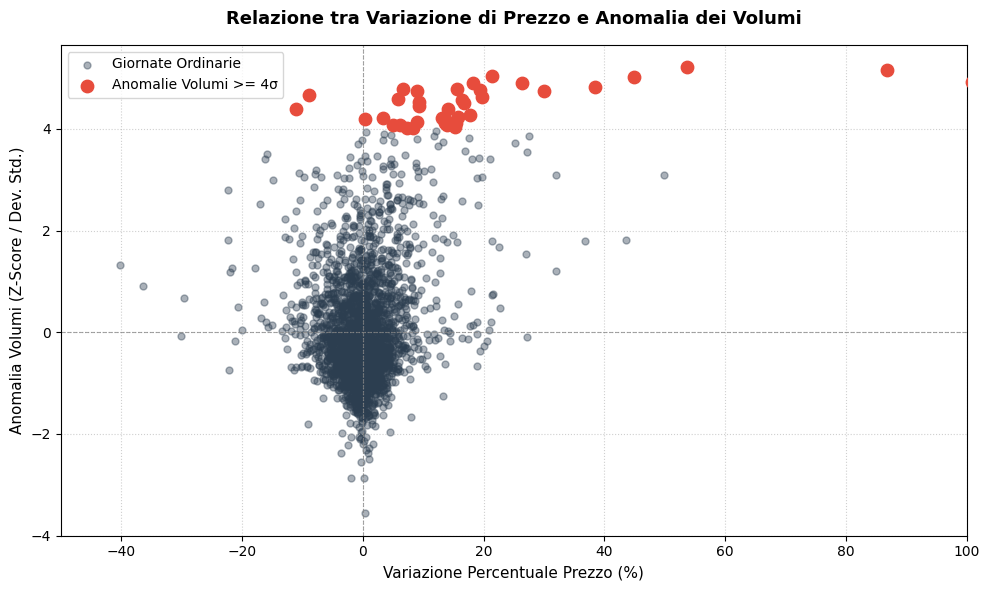

In [43]:
import matplotlib.pyplot as plt
import pandas as pd

fig, ax = plt.subplots(figsize=(10, 6))

x_col = "Price_Change_Pct"

# Controlliamo ed eventualmente calcoliamo 'Volume_ZScore' se non esiste nel DataFrame
if "Volume_ZScore" not in df.columns:
  vol_ma = df["Volume"].rolling(window=30).mean()
  vol_std = df["Volume"].rolling(window=30).std()
  df["Volume_ZScore"] = (df["Volume"] - vol_ma) / vol_std

y_col = "Volume_ZScore"

# Scatter plot di tutte le giornate ordinarie
ax.scatter(
    df[x_col],
    df[y_col],
    color="#2c3e50",
    alpha=0.4,
    s=25,
    label="Giornate Ordinarie",
)

# Evidenziamo in rosso i punti estremi con anomalie sui volumi >= 4 deviazioni standard
extreme_vol = df[df["Volume_ZScore"] >= 4.0]
ax.scatter(
    extreme_vol[x_col],
    extreme_vol[y_col],
    color="#e74c3c",
    s=80,
    zorder=5,
    label="Anomalie Volumi >= 4σ",
)

# Linee di riferimento per gli assi zero
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)

# LIMITIAMO L'ASSE X TRA -50% E +100%
ax.set_xlim(-50, 100)

# Personalizzazione estetica
ax.set_title(
    (
        "Relazione tra Variazione di Prezzo e Anomalia dei Volumi"
    ),
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Variazione Percentuale Prezzo (%)", fontsize=11)
ax.set_ylabel("Anomalia Volumi (Z-Score / Dev. Std.)", fontsize=11)

ax.legend(fontsize=10, loc="upper left")
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

La stragrande maggioranza degli outlier (4 deviazioni standard dalla media) indica grosse variazioni % di prezzo

ANALISI DI CONCENTRAZIONE DEI VOLUMI (REGOLA DI PARETO) - DOGE
Totale giorni storici analizzati: 2923
👉 Il TOP 1% dei giorni di scambio concentra ben il **18.32%** del volume totale storico!
👉 Il TOP 0.1% dei giorni concentra il **3.85%** del volume totale.


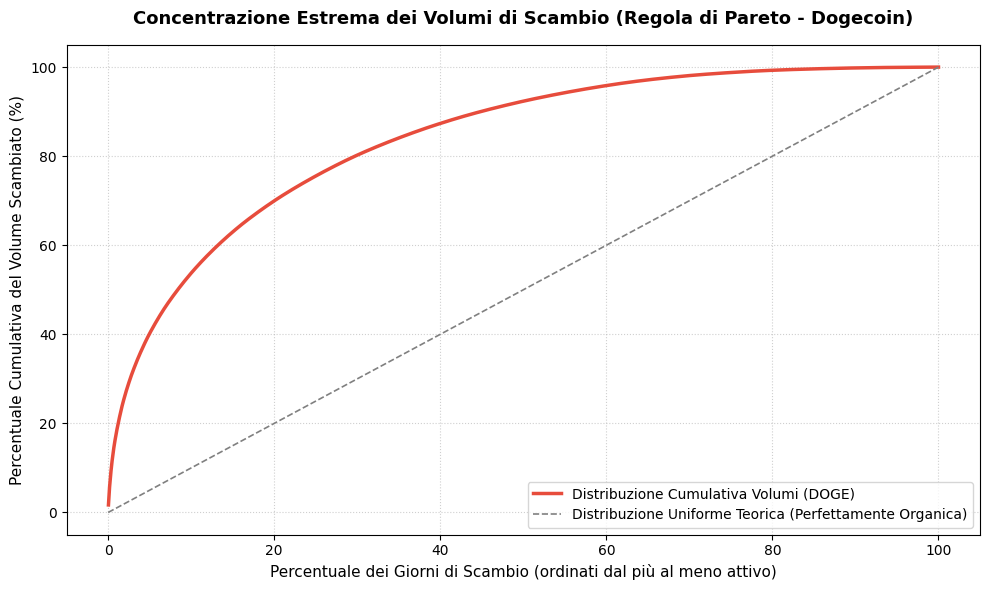

In [44]:
# Assicuriamoci di prendere i volumi ripuliti dai valori nulli dal dataframe esistente
volumes = df["Volume"].dropna().sort_values(ascending=False).values
total_volume = volumes.sum()

# Calcoliamo le percentuali cumulative
cum_volume_pct = np.cumsum(volumes) / total_volume * 100
cum_days_pct = np.arange(1, len(volumes) + 1) / len(volumes) * 100

# Metriche chiave (Top 1% e Top 0.1% dei giorni più attivi)
idx_1pct = int(len(volumes) * 0.01)
vol_top_1pct = cum_volume_pct[idx_1pct]

idx_01pct = int(len(volumes) * 0.001)
vol_top_01pct = (
    cum_volume_pct[idx_01pct] if idx_01pct > 0 else cum_volume_pct[0]
)

print("=" * 60)
print("ANALISI DI CONCENTRAZIONE DEI VOLUMI (REGOLA DI PARETO) - DOGE")
print("=" * 60)
print(f"Totale giorni storici analizzati: {len(volumes)}")
print(
    f"👉 Il TOP 1% dei giorni di scambio concentra ben il"
    f" **{vol_top_1pct:.2f}%** del volume totale storico!"
)
if idx_01pct > 0:
  print(
      f"👉 Il TOP 0.1% dei giorni concentra il **{vol_top_01pct:.2f}%** del"
      " volume totale."
  )
print("=" * 60)

# Grafico della Curva di Concentrazione (Lorenz Curve)
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    cum_days_pct,
    cum_volume_pct,
    color="#e74c3c",
    linewidth=2.5,
    label="Distribuzione Cumulativa Volumi (DOGE)",
)
ax.plot(
    [0, 100],
    [0, 100],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="Distribuzione Uniforme Teorica (Perfettamente Organica)",
)

ax.set_title(
    (
        "Concentrazione Estrema dei Volumi di Scambio (Regola di Pareto -"
        " Dogecoin)"
    ),
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel(
    "Percentuale dei Giorni di Scambio (ordinati dal più al meno attivo)",
    fontsize=11,
)
ax.set_ylabel("Percentuale Cumulativa del Volume Scambiato (%)", fontsize=11)

ax.legend(fontsize=10, loc="lower right")
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Perché è una prova chiave di manipolazione / P&D?
Questo grafico smaschera visivamente l'assenza di una liquidità sana, costante o legata a un'adozione organica dell'asset. Dimostra che il mercato di Dogecoin è completamente episodico e reattivo: i volumi si accendono in modo violento e spropositato solo durante le rare ondate di isteria collettiva e speculazione pilotata (i pump), per poi spegnersi nei periodi intermedi.
Nello specifico: nel circa 20% dei giorni è stato scambiato il 75% del volume

ANALISI DELLA CURTOSI E DELLE CODE GRASSE (FAT TAILS) - DOGE
Media dei ritorni giornalieri: 0.34%
Deviazione standard: 8.92%
Asimmetria (Skewness): 22.71 (spinta verso i rialzi)
Curtosi in eccesso (Excess Kurtosis): **866.89** (In una distribuzione normale ideale sarebbe 0!)


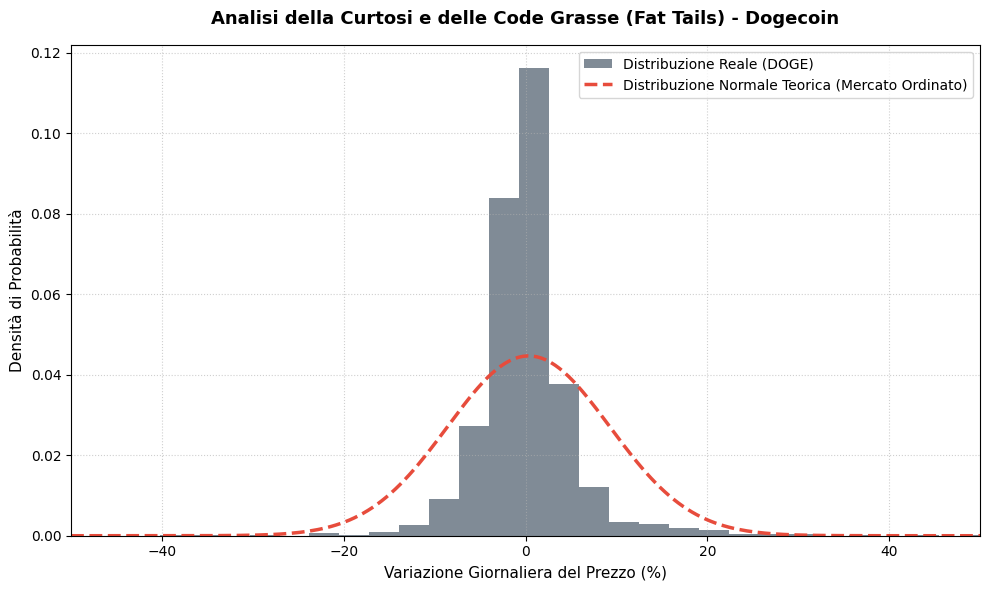

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kurtosis, norm, skew

# Assicuriamoci che esista la colonna dei ritorni percentuali giornalieri
if "Price_Change_Pct" not in df.columns:
  df["Price_Change_Pct"] = df["Close"].pct_change() * 100

returns = df["Price_Change_Pct"].dropna()

# Calcoliamo le metriche statistiche chiave
mu, std = norm.fit(returns)
excess_kurt = kurtosis(
    returns
)  # Curtosi in eccesso (Fisher: la normale ha curtosi = 0)
sk = skew(returns)

print("=" * 60)
print("ANALISI DELLA CURTOSI E DELLE CODE GRASSE (FAT TAILS) - DOGE")
print("=" * 60)
print(f"Media dei ritorni giornalieri: {mu:.2f}%")
print(f"Deviazione standard: {std:.2f}%")
print(f"Asimmetria (Skewness): {sk:.2f} (spinta verso i rialzi)")
print(
    f"Curtosi in eccesso (Excess Kurtosis): **{excess_kurt:.2f}** "
    "(In una distribuzione normale ideale sarebbe 0!)"
)
print("=" * 60)

# Grafico della distribuzione reale vs Normale teorica
fig, ax = plt.subplots(figsize=(10, 6))

# Istogramma dei ritorni reali di Dogecoin
count, bins, ignored = ax.hist(
    returns,
    bins=120,
    density=True,
    alpha=0.6,
    color="#2c3e50",
    label="Distribuzione Reale (DOGE)",
)

# Curva normale teorica di confronto (con stessa media e deviazione standard)
xmin, xmax = ax.set_xlim(-50, 50)  # Limitiamo lo zoom centrale per chiarezza
x = np.linspace(-50, 50, 200)
p = norm.pdf(x, mu, std)
ax.plot(
    x,
    p,
    color="#e74c3c",
    linestyle="--",
    linewidth=2.5,
    label="Distribuzione Normale Teorica (Mercato Ordinato)",
)

ax.set_title(
    "Analisi della Curtosi e delle Code Grasse (Fat Tails) - Dogecoin",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Variazione Giornaliera del Prezzo (%)", fontsize=11)
ax.set_ylabel("Densità di Probabilità", fontsize=11)

ax.legend(fontsize=10, loc="upper right")
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

ANALISI DELLA CURTOSI - BITCOIN (BTC-USD) DI CONTROLLO
Curtosi in eccesso (Excess Kurtosis) di Bitcoin: **8.45**
Asimmetria (Skewness) di Bitcoin: -0.28


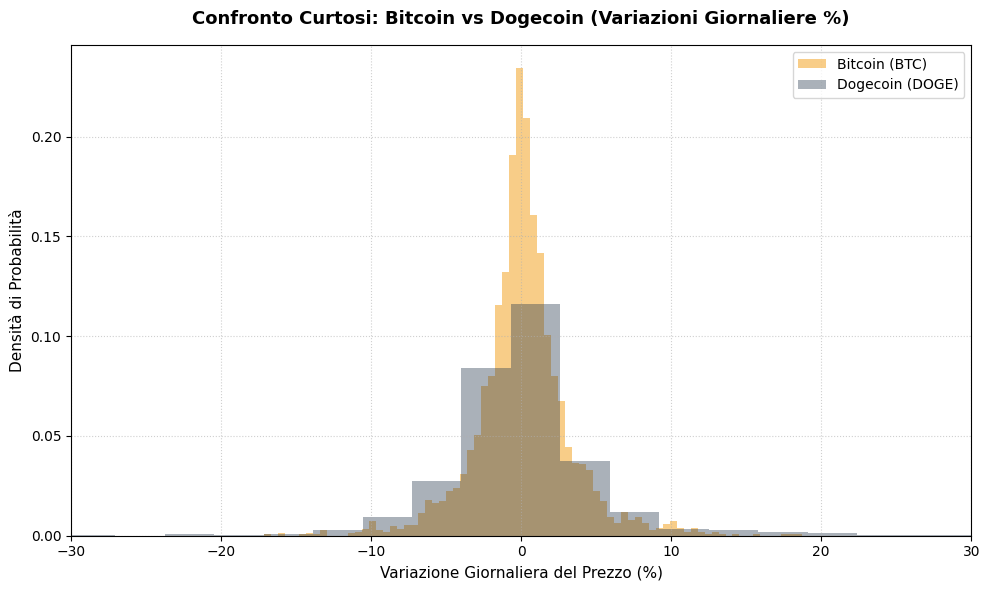

In [47]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from scipy.stats import kurtosis, norm, skew

# 1. Scarichiamo i dati storici di Bitcoin (stesso orizzonte temporale)
df_btc = yf.download("BTC-USD", start="2018-01-01", progress=False)
if isinstance(df_btc.columns, pd.MultiIndex):
  df_btc.columns = df_btc.columns.get_level_values(0)

# 2. Calcoliamo i ritorni percentuali giornalieri per Bitcoin
returns_btc = df_btc["Close"].pct_change().dropna() * 100

# 3. Metriche statistiche per Bitcoin
excess_kurt_btc = kurtosis(returns_btc)
sk_btc = skew(returns_btc)

print("=" * 60)
print("ANALISI DELLA CURTOSI - BITCOIN (BTC-USD) DI CONTROLLO")
print("=" * 60)
print(f"Curtosi in eccesso (Excess Kurtosis) di Bitcoin: **{excess_kurt_btc:.2f}**")
print(f"Asimmetria (Skewness) di Bitcoin: {sk_btc:.2f}")
print("=" * 60)

# 4. Confronto visivo delle distribuzioni (DOGE vs BTC)
fig, ax = plt.subplots(figsize=(10, 6))

# Istogramma Bitcoin
ax.hist(
    returns_btc,
    bins=120,
    density=True,
    alpha=0.5,
    color="#f39c12",
    label="Bitcoin (BTC)",
)
# Istogramma Dogecoin (già calcolato prima)
ax.hist(
    returns,
    bins=120,
    density=True,
    alpha=0.4,
    color="#2c3e50",
    label="Dogecoin (DOGE)",
)

ax.set_xlim(-30, 30)  # Zoom centrale per apprezzare la differenza di picco
ax.set_title(
    "Confronto Curtosi: Bitcoin vs Dogecoin (Variazioni Giornaliere %)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Variazione Giornaliera del Prezzo (%)", fontsize=11)
ax.set_ylabel("Densità di Probabilità", fontsize=11)

ax.legend(fontsize=10, loc="upper right")
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

CONFRONTO CONCENTRAZIONE VOLUMI (TOP 1% DEI GIORNI)
👉 Bitcoin (BTC) - Il top 1% dei giorni copre il 4.16% del volume totale
👉 Dogecoin (DOGE) - Il top 1% dei giorni copre il 18.32% del volume totale


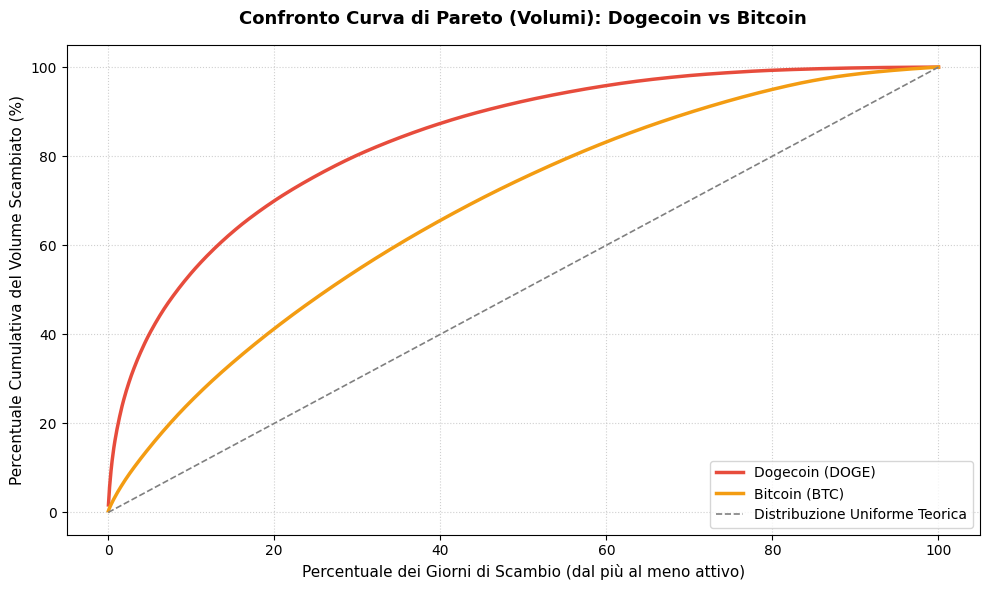

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Calcoliamo la concentrazione di Pareto per Bitcoin (usando df_btc già scaricato prima)
volumes_btc = df_btc["Volume"].dropna().sort_values(ascending=False).values
total_volume_btc = volumes_btc.sum()

cum_volume_btc_pct = np.cumsum(volumes_btc) / total_volume_btc * 100
cum_days_btc_pct = np.arange(1, len(volumes_btc) + 1) / len(volumes_btc) * 100

# Metrica chiave top 1% per Bitcoin
idx_1pct_btc = int(len(volumes_btc) * 0.01)
vol_top_1pct_btc = cum_volume_btc_pct[idx_1pct_btc]

# Ricicalcoliamo anche per Dogecoin per sicurezza (se non in memoria)
volumes_doge = df["Volume"].dropna().sort_values(ascending=False).values
total_volume_doge = volumes_doge.sum()
cum_volume_doge_pct = np.cumsum(volumes_doge) / total_volume_doge * 100
cum_days_doge_pct = (
    np.arange(1, len(volumes_doge) + 1) / len(volumes_doge) * 100
)
idx_1pct_doge = int(len(volumes_doge) * 0.01)
vol_top_1pct_doge = cum_volume_doge_pct[idx_1pct_doge]

print("=" * 60)
print("CONFRONTO CONCENTRAZIONE VOLUMI (TOP 1% DEI GIORNI)")
print("=" * 60)
print(f"👉 Bitcoin (BTC) - Il top 1% dei giorni copre il {vol_top_1pct_btc:.2f}% del volume totale")
print(f"👉 Dogecoin (DOGE) - Il top 1% dei giorni copre il {vol_top_1pct_doge:.2f}% del volume totale")
print("=" * 60)

# 2. Grafico comparativo delle Curve di Lorenz
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(cum_days_doge_pct, cum_volume_doge_pct, color="#e74c3c", linewidth=2.5, label="Dogecoin (DOGE)")
ax.plot(cum_days_btc_pct, cum_volume_btc_btc_pct if 'cum_volume_btc_btc_pct' in locals() else cum_volume_btc_pct, color="#f39c12", linewidth=2.5, label="Bitcoin (BTC)")

# Diagonale teorica di perfetta uguaglianza
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1.2, label="Distribuzione Uniforme Teorica")

ax.set_title("Confronto Curva di Pareto (Volumi): Dogecoin vs Bitcoin", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Percentuale dei Giorni di Scambio (dal più al meno attivo)", fontsize=11)
ax.set_ylabel("Percentuale Cumulativa del Volume Scambiato (%)", fontsize=11)

ax.legend(fontsize=10, loc="lower right")
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

CONFRONTO DI CONTROLLO: DOGECOIN VS CARDANO (ADA)
👉 Curtosi in Eccesso:
   - Dogecoin (DOGE): 866.89
   - Cardano (ADA):   14.14
------------------------------------------------------------
👉 Concentrazione Volumi (Top 1% dei giorni):
   - Dogecoin (DOGE): 18.32% del volume totale
   - Cardano (ADA):   11.88% del volume totale


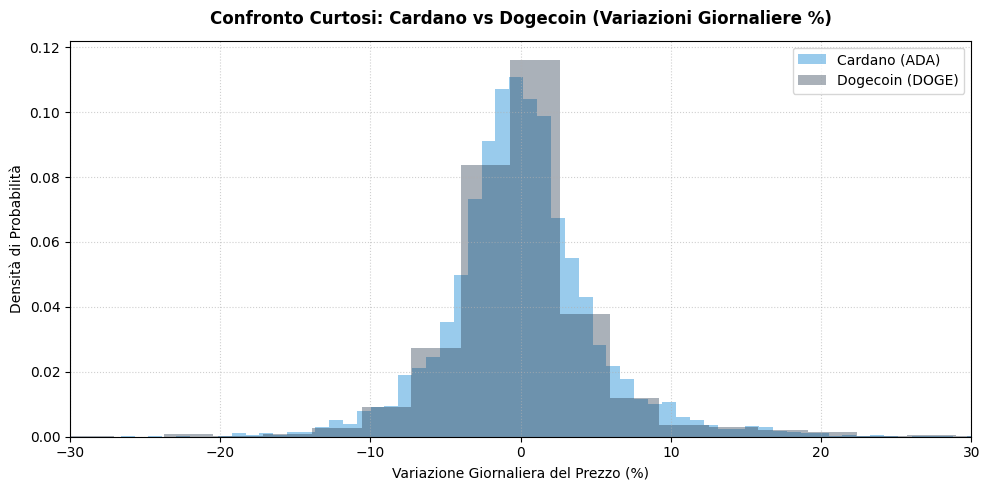

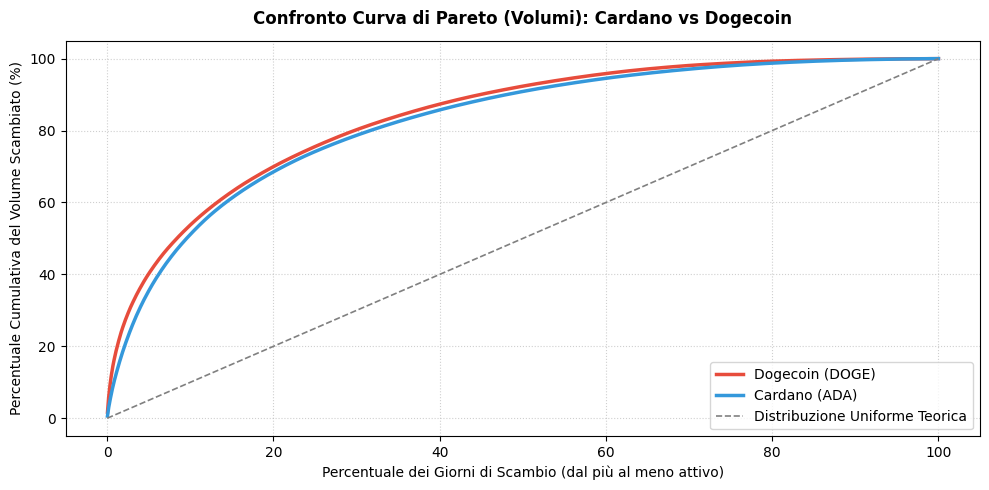

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from scipy.stats import kurtosis, norm, skew

# 1. Scarichiamo i dati di Cardano (ADA-USD) con lo stesso orizzonte temporale
df_ada = yf.download("ADA-USD", start="2018-01-01", progress=False)
if isinstance(df_ada.columns, pd.MultiIndex):
  df_ada.columns = df_ada.columns.get_level_values(0)

# 2. Ritorni percentuali e metriche per Cardano
returns_ada = df_ada["Close"].pct_change().dropna() * 100
excess_kurt_ada = kurtosis(returns_ada)
sk_ada = skew(returns_ada)

# 3. Concentrazione di Pareto per Cardano
volumes_ada = df_ada["Volume"].dropna().sort_values(ascending=False).values
total_volume_ada = volumes_ada.sum()
cum_volume_ada_pct = np.cumsum(volumes_ada) / total_volume_ada * 100
cum_days_ada_pct = np.arange(1, len(volumes_ada) + 1) / len(volumes_ada) * 100

idx_1pct_ada = int(len(volumes_ada) * 0.01)
vol_top_1pct_ada = cum_volume_ada_pct[idx_1pct_ada]

# Stampiamo il confronto numerico definitivo
print("=" * 60)
print("CONFRONTO DI CONTROLLO: DOGECOIN VS CARDANO (ADA)")
print("=" * 60)
print(f"👉 Curtosi in Eccesso:")
print(f"   - Dogecoin (DOGE): {excess_kurt:.2f}")
print(f"   - Cardano (ADA):   {excess_kurt_ada:.2f}")
print("-" * 60)
print(f"👉 Concentrazione Volumi (Top 1% dei giorni):")
print(f"   - Dogecoin (DOGE): {vol_top_1pct_doge:.2f}% del volume totale")
print(f"   - Cardano (ADA):   {vol_top_1pct_ada:.2f}% del volume totale")
print("=" * 60)

# --- GRAFICO 1: Confronto Curtosi / Code Grasse ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(
    returns_ada,
    bins=120,
    density=True,
    alpha=0.5,
    color="#3498db",
    label="Cardano (ADA)",
)
ax.hist(
    returns,
    bins=120,
    density=True,
    alpha=0.4,
    color="#2c3e50",
    label="Dogecoin (DOGE)",
)
ax.set_xlim(-30, 30)
ax.set_title(
    "Confronto Curtosi: Cardano vs Dogecoin (Variazioni Giornaliere %)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Variazione Giornaliera del Prezzo (%)", fontsize=10)
ax.set_ylabel("Densità di Probabilità", fontsize=10)
ax.legend(fontsize=10, loc="upper right")
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# --- GRAFICO 2: Confronto Curve di Pareto (Lorenz) ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    cum_days_doge_pct,
    cum_volume_doge_pct,
    color="#e74c3c",
    linewidth=2.5,
    label="Dogecoin (DOGE)",
)
ax.plot(
    cum_days_ada_pct,
    cum_volume_ada_pct,
    color="#3498db",
    linewidth=2.5,
    label="Cardano (ADA)",
)
ax.plot(
    [0, 100],
    [0, 100],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="Distribuzione Uniforme Teorica",
)
ax.set_title(
    "Confronto Curva di Pareto (Volumi): Cardano vs Dogecoin",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel(
    "Percentuale dei Giorni di Scambio (dal più al meno attivo)", fontsize=10
)
ax.set_ylabel("Percentuale Cumulativa del Volume Scambiato (%)", fontsize=10)
ax.legend(fontsize=10, loc="lower right")
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()